# Utilities

## Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import re, string, joblib, umap, time, pickle
import numpy as np
from collections import Counter

# Natural language processing
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

# Data science
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN

# Visualization
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px

# Hierarchical clustering
from fastcluster import linkage
from scipy.cluster.hierarchy import dendrogram, fcluster
from scipy.spatial.distance import pdist

# Words cloud
from wordcloud import WordCloud

In [2]:
# # Basicas
# import seaborn as sns
# import os, time, pickle, pydot, joblib, kaleido, json

# from mpl_toolkits.mplot3d import Axes3D

# # Ciencia de datos
# from scipy.spatial.distance import pdist
# from sklearn.metrics.pairwise import euclidean_distances

# from sklearn.preprocessing import normalize


# from sklearn.decomposition import LatentDirichletAllocation
# from scipy.sparse import csr_matrix


# # visualizacion
# from yellowbrick.cluster import KElbowVisualizer
# import networkx as nx
# from IPython.display import Image, display
# from graphviz import Digraph

# # otros modelos
# import gensim, spacy
# # Cargar el modelo de spaCy
# nlp = spacy.load('en_core_web_sm')

# from gensim import corpora
# from gensim.models import LsiModel
# from gensim.parsing.preprocessing import preprocess_string

## Functions

In [3]:
# Text preprocessing
def preprocess_text(text, words2remove):
    text = text.lower()                                                  # Lower case
    text = re.sub(r'[^a-z\s]', ' ', text)                                # Remove numbers and special characteres
    # split(r'\s+') is the same as word_tokenize()
    # if the text doesn´t have special characters
    # text = text.split(r'\s+')                                          # Remove multiple spaces, convert to list
    tokens = word_tokenize(text)                                         # Tokenization
    tokens = [word for word in tokens if word not in stop_words]         # Remove stopwords
    tokens = [word for word in tokens if word not in string.punctuation] # Remove punctuation
    tokens = [word for word in tokens if word not in words2remove]       # Remove words from custom list
    tokens = [lemmatizer.lemmatize(word) for word in tokens]             # Lemmatization
    return ' '.join(tokens)

# Word clouds for given string
def word_cloud(text):
    w = 10
    h = 5
    word_freq = Counter(text.split(' '))
    wordcloud = WordCloud(width=w * 100, height=h * 100,
                           background_color='white',
                           stopwords=None,
                           min_font_size=10).generate_from_frequencies(word_freq)
    plt.figure(figsize=(w, h), facecolor=None)
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.tight_layout(pad=0)
    plt.show()

# Load data

In [4]:
data = pd.read_csv('../data/input/api/data_filtered.csv')
data.shape

(6719, 7)

In [5]:
df = pd.read_csv('../data/input/api/data_cleaned.csv')
df.shape

(6719, 4)

In [6]:
df_vectorized = pd.read_csv('../data/output/df_vectorized.csv')
X = df_vectorized.values
X.shape

(6719, 15471)

In [7]:
words2remove = []

In [8]:
vectorizer = joblib.load('../models/vectorizer.pkl')
words = vectorizer.get_feature_names_out()

Dimensionality reduction

Keep 95% of explained variance

In [9]:
explained_variance_ratio_goal = 0.95
pca = PCA(n_components=explained_variance_ratio_goal)
pca.fit(df_vectorized)
n_components = pca.n_components_
n_components

2521

In [10]:
X_original = X.copy()
df_vectorized_original = df_vectorized.copy()

# X = PCA(n_components=n_components).fit_transform(X) # Specify number of components
X = pca.transform(X) # Use fitted PCA with 95% of explained variance
df_vectorized = pd.DataFrame(X)

# Normalize
X = X / np.linalg.norm(X, axis=1, keepdims=True)
df_vectorized = pd.DataFrame(X)

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


# KNN search

In [11]:
n_neighbors = 100
knn = NearestNeighbors(n_neighbors=n_neighbors, metric='cosine', algorithm='brute').fit(X)

# Query text

# query_text = "reinforcement learning control modular multilevel matrix converter"
# query_text = "reinforcement learning control modular power converter"
# query_text = "physics informed reinforcement learning"
# query_text = "reinforcement learning"
# query_text = "control power converter balance capacitor"
# query_text = "artificial intelligence reinforcement learning control power converter balance capacitor"
# query_text = 'modular multilevel matrix converter'
query_text = "The artificial intelligence, deep learning, imitation learning, reinforcement learning, and neural networks in power converters."
print(query_text)

# Preprocessing
query_text = [preprocess_text(query_text, words2remove)]
print(query_text)

# Vectorize
query_text_vec = pca.transform(vectorizer.transform(query_text))
print(query_text_vec)

# Calculate KNNs
knn_distances, knn_idxs = knn.kneighbors(query_text_vec.reshape(1, -1))

for i, knn_idx in enumerate(knn_idxs[0]):
    print(i)
    print(knn_idx)
    display(f"Neighbor {i+1}:")
    display(f"Title: {data['title'][knn_idx]}")
    display(f"Abstract: {data['abstract'][knn_idx]}")
    display(f"Abstract: {data['html_url'][knn_idx]}")    
    print("-"*40)

The artificial intelligence, deep learning, imitation learning, reinforcement learning, and neural networks in power converters.
['artificial intelligence deep learning imitation learning reinforcement learning neural network power converter']


f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


[[ 0.03488642 -0.01197237  0.02480152 ... -0.00169011 -0.00275682
  -0.00314874]]
0
1819


'Neighbor 1:'

'Title: application of neural network controller and policy gradient reinforcement learning on modular multilevel converter mmc a proof of concept'

...

'Neighbor 100:'

'Title: contents'

'Abstract: the following topics are dealt with modular multilevel converters electrical distribution network supercapacitor thermoelectric cooling systems wireless sensor networks electrostatic space protection meshed multiterminal dc grids patch antenna ultrasonic sensor magnetic filter plasma aided surface impregnation smes device electric machines smart grid dc electromagnetic actuator electrical insulation risk management oil immersed distribution transformer dual star induction generator driven wind turbine digital image processing power cables power electronic microhydropower plant synchronous generator electric vehicle induction heating and explosion proof mv switchgear structure'

'Abstract: https://ieeexplore.ieee.org/document/7542979/'

----------------------------------------


# Dimensionality reduction

### PCA

In [12]:
# # PCA 2D
# X_pca_2d = PCA(n_components=2).fit_transform(df_vectorized)
# df['pca2d_1'] = X_pca_2d[:, 0]
# df['pca2d_2'] = X_pca_2d[:, 1]

# # PCA 3D
# X_pca_3d = PCA(n_components=3).fit_transform(df_vectorized)
# df['pca3d_1'] = X_pca_3d[:, 0]
# df['pca3d_2'] = X_pca_3d[:, 1]
# df['pca3d_3'] = X_pca_3d[:, 2]

# # Graficar
# colors = np.ones(len(df))  # Color base
# colors_knn = np.zeros(len(df))  # Color para los KNN
# colors_knn[knn_idxs[0]] = 1  # Resaltar los KNN

# fig = make_subplots(rows=1, cols=2, subplot_titles=("PCA 2D", "PCA 3D"), 
#                     specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# # Puntos normales (fondo)
# fig.add_trace(
#     go.Scatter(x=df['pca2d_1'], y=df['pca2d_2'], mode='markers',
#                marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
#                text=data['title'],
#                hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
#     row=1, col=1)

# # Puntos resaltados (delante)
# fig.add_trace(
#     go.Scatter(x=df.loc[knn_idxs[0], 'pca2d_1'], 
#                y=df.loc[knn_idxs[0], 'pca2d_2'], 
#                mode='markers',
#                marker=dict(color='red', size=5, opacity=1), 
#                text=data.loc[knn_idxs[0], 'title'], 
#                hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
#     row=1, col=1)

# # Puntos normales en 3D (fondo)
# fig.add_trace(
#     go.Scatter3d(x=df['pca3d_1'], y=df['pca3d_2'], z=df['pca3d_3'], mode='markers',
#                  marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
#                  text=data['title'],
#                  hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
#     row=1, col=2)

# # Puntos resaltados en 3D (delante)
# fig.add_trace(
#     go.Scatter3d(x=df.loc[knn_idxs[0], 'pca3d_1'], 
#                  y=df.loc[knn_idxs[0], 'pca3d_2'], 
#                  z=df.loc[knn_idxs[0], 'pca3d_3'], 
#                  mode='markers',
#                  marker=dict(color='red', size=5, opacity=1), 
#                  text=data.loc[knn_idxs[0], 'title'], 
#                  hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
#     row=1, col=2)

# fig.update_layout(height=600, width=1200, title_text="PCA 2D y 3D", showlegend=False)
# fig.show()

### UMAP

In [13]:
# n_neighbors = 200
# n_neighbors = int(len(df) / k)

# n_neighbors = 200
n_neighbors = 50 # 6.5x minutos, resultado: vision mas global, no se distinguen tanto los clusters
# n_neighbors = 20 # 2.5x minutos, resultado: no se distinguen los clusters
# n_neighbors = 10 # 1.5x minutos, resultado: puntos muy juntos, se distinguen los clusters
# n_neighbors = 5 # x minutos, resultado: se distinguen bien los clusters, se ven un poco desconectados

min_dist = 0

# UMAP 2D
reducer_2d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=2, random_state=0, metric='cosine')
embedding_2d = reducer_2d.fit_transform(df_vectorized)
df['umap2d_1'] = embedding_2d[:, 0]
df['umap2d_2'] = embedding_2d[:, 1]

# UMAP 3D
reducer_3d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=3, random_state=0, metric='cosine')
embedding_3d = reducer_3d.fit_transform(df_vectorized)
df['umap3d_1'] = embedding_3d[:, 0]
df['umap3d_2'] = embedding_3d[:, 1]
df['umap3d_3'] = embedding_3d[:, 2]

# Graficar
colors = np.ones(len(df))  # Color base
colors_knn = np.zeros(len(df))  # Color para los KNN
colors_knn[knn_idxs[0]] = 1  # Resaltar los KNN

fig = make_subplots(rows=1, cols=2, subplot_titles=("UMAP 2D", "UMAP 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales (fondo)
fig.add_trace(
    go.Scatter(x=df['umap2d_1'], y=df['umap2d_2'], mode='markers',
               marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
               text=data['title'],
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados (delante)
fig.add_trace(
    go.Scatter(x=df.loc[knn_idxs[0], 'umap2d_1'], 
               y=df.loc[knn_idxs[0], 'umap2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=data.loc[knn_idxs[0], 'title'], 
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D (fondo)
fig.add_trace(
    go.Scatter3d(x=df['umap3d_1'], y=df['umap3d_2'], z=df['umap3d_3'], mode='markers',
                 marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
                 text=data['title'],
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D (delante)
fig.add_trace(
    go.Scatter3d(x=df.loc[knn_idxs[0], 'umap3d_1'],
                 y=df.loc[knn_idxs[0], 'umap3d_2'],
                 z=df.loc[knn_idxs[0], 'umap3d_3'],
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=data.loc[knn_idxs[0], 'title'], 
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="UMAP 2D y 3D", showlegend=False)
fig.show()

c:\Users\Ingeniería Eléctrica\Desktop\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\Ingeniería Eléctrica\Desktop\TESIS\SOTA\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\Ingeniería Eléctrica\Desktop\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\Ingeniería Eléctrica\Desktop\TESIS\SOTA\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


### Autoencoder

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

# X: matriz de datos previamente escalados
input_dim = X.shape[1]
encoding_dim = 2  # proyección 2D

# Definir arquitectura del autoencoder
input_layer = Input(shape=(input_dim,))
encoded = Dense(128, activation='relu')(input_layer)
encoded = Dense(64, activation='relu')(encoded)
bottleneck = Dense(encoding_dim, activation='linear')(encoded)

decoded = Dense(64, activation='relu')(bottleneck)
decoded = Dense(128, activation='relu')(decoded)
output_layer = Dense(input_dim, activation='linear')(decoded)

# Construir el modelo
autoencoder = Model(inputs=input_layer, outputs=output_layer)
autoencoder.compile(optimizer='adam', loss='mse')

# Entrenamiento
autoencoder.fit(X, X, epochs=50, batch_size=32, shuffle=True, verbose=1)

# Crear modelo encoder para la proyección 2D
encoder = Model(inputs=input_layer, outputs=bottleneck)
X_encoded = encoder.predict(X)

# Visualización
plt.figure(figsize=(8, 6))
plt.scatter(X_encoded[:, 0], X_encoded[:, 1], s=10, alpha=0.7)
plt.title('Proyección 2D usando Autoencoder')
plt.xlabel('Dim 1')
plt.ylabel('Dim 2')
plt.grid(True)
plt.tight_layout()
plt.show()

ImportError: cannot import name 'pywrap_tensorflow' from 'tensorflow.python' (f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\tensorflow\python\__init__.py)

## Plot KNN

In [14]:
reduced_zero = reducer_2d.transform(np.zeros(df_vectorized.shape[1]).reshape(1, -1))
reduced_knn = reducer_2d.transform(df_vectorized.iloc[knn_idxs[0]])
reduced_query = reducer_2d.transform(query_text_vec)

knn_distances = knn_distances.flatten()
reduced_knn.shape, reduced_query.shape, knn_distances.shape, reduced_zero

d:\Users\Pablo\Desktop\Tesis\SOTA\.venv\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

d:\Users\Pablo\Desktop\Tesis\SOTA\.venv\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

d:\Users\Pablo\Desktop\Tesis\SOTA\.venv\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



((100, 2), (1, 2), (100,), array([[1.2427174, 9.221842 ]], dtype=float32))

In [59]:
knn_distances = knn_distances[::-1]

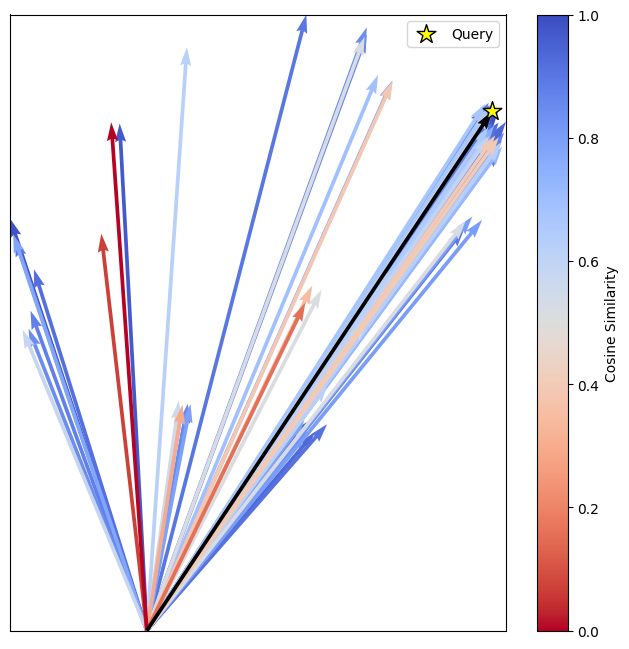

In [60]:
# Asegúrate de que las distancias estén normalizadas entre 0 y 1
exp = 1
knn_distances_normalized = (knn_distances**exp - min(knn_distances**exp)) / (max(knn_distances**exp) - min(knn_distances**exp))

# Graficar
plt.figure(figsize=(8, 8))

# Crear un mapa de colores para las distancias normalizadas
norm = plt.Normalize(vmin=0, vmax=1)  # Normalización de las distancias
sm = plt.cm.ScalarMappable(cmap="coolwarm_r", norm=norm)  # Invertir el colormap con "coolwarm_r"
sm.set_array([])  # Necesario para que la barra de colores funcione

# 2. Graficar los vectores de los vecinos más cercanos (KNN)
for i in range(reduced_knn.shape[0]):
    knn_point = reduced_knn[i]
    color = sm.to_rgba(knn_distances_normalized[i])  # Obtener el color correspondiente a la distancia
    plt.quiver(reduced_zero[0, 0], reduced_zero[0, 1], knn_point[0], knn_point[1], angles='xy', scale_units='xy', scale=1, color=color)

# 1. Graficar el vector de consulta (query vector)
query_point = reduced_query[0]
plt.quiver(reduced_zero[0, 0], reduced_zero[0, 1], query_point[0], query_point[1], angles='xy', scale_units='xy', scale=1, color='black')
# Añadir una estrella para el vector de consulta (usamos plt.scatter)
plt.scatter(reduced_zero[0, 0]+query_point[0], reduced_zero[0, 1]+query_point[1], color='yellow', s=200, marker='*', label='Query', edgecolors='black')

# Configuración del gráfico
# plt.gca().set_aspect('equal', adjustable='box')
# plt.title('Query Vector and KNN Vectors')
plt.autoscale(True)
# plt.xlabel('umap2d_1')
# plt.ylabel('umap2d_2')
plt.xticks([])
plt.yticks([])
plt.xlim([min(reduced_zero[0, 0], reduced_zero[0, 0]+query_point[0], reduced_zero[0, 0]+reduced_knn[:,0].min()), max(reduced_zero[0, 0]+query_point[0], reduced_zero[0, 0]+reduced_knn[:,0].max())])
plt.ylim([min(reduced_zero[0, 1], reduced_zero[0, 1]+query_point[1], reduced_zero[0, 1]+reduced_knn[:,1].min()), max(reduced_zero[0, 1]+query_point[1], reduced_zero[0, 1]+reduced_knn[:,1].max())])
plt.legend()
plt.colorbar(sm, label='Cosine Similarity', ax=plt.gca())
plt.savefig('../data/output/knn.pdf', format='pdf')
plt.show()


# Clustering

## Hierarchical

In [17]:
# methods = ['single', 'complete', 'average', 'weighted', 'centroid', 'ward']
# metrics = ['braycurtis', 'canberra', 'chebyshev', 'cityblock', 'correlation', 'cosine', 'dice', 'euclidean', 'hamming', 'jaccard', 'jensenshannon', 'kulczynski1', 'mahalanobis', 'matching', 'minkowski', 'rogerstanimoto', 'russellrao', 'seuclidean', 'sokalmichener', 'sokalsneath', 'sqeuclidean', 'yule']

methods = ['average', 'complete', 'weighted', 'ward']
metrics = ['cosine', 'jensenshannon', 'correlation']

method = 'ward'
metric = 'cosine'

In [18]:
# Create hierarchical clustering with provided distance matrix
Z = linkage(X, method=method, metric=metric)

# Save clustering
joblib.dump(Z, '../data/output/hierarchical_cluster_Z.joblib')

['../data/output/hierarchical_cluster_Z.joblib']

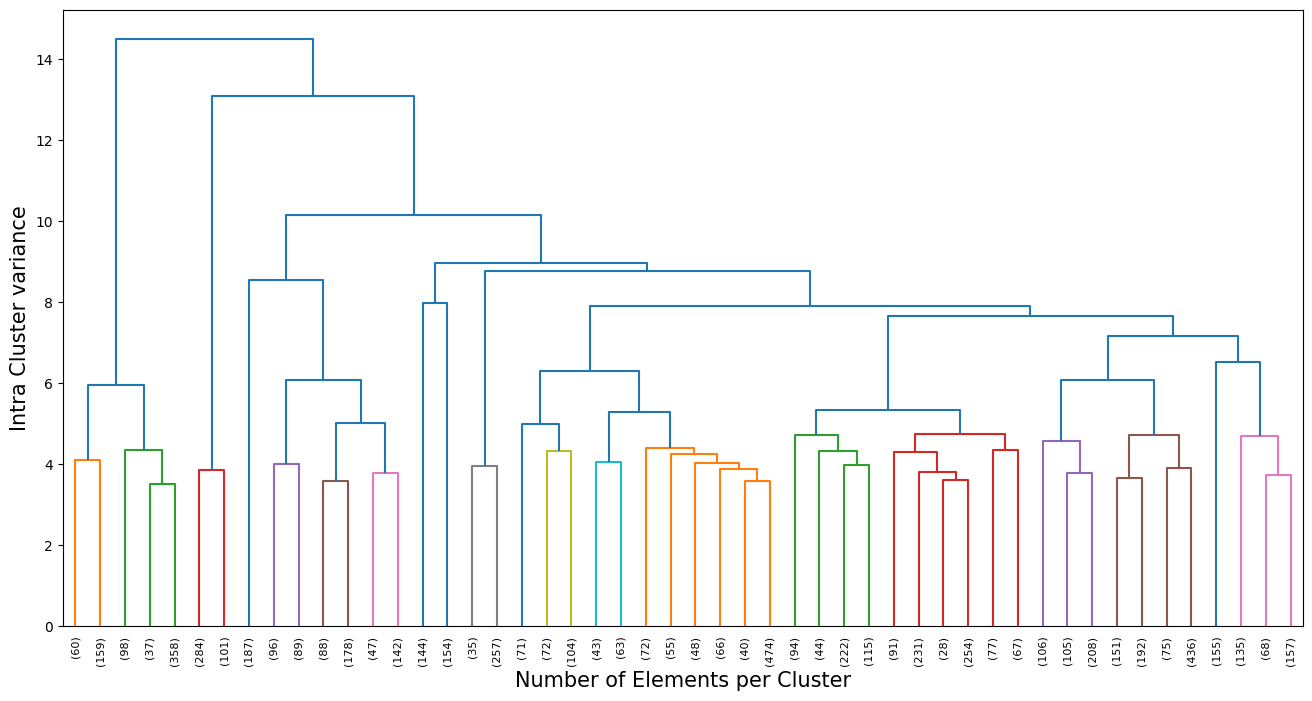

In [19]:
# Load hierarchical clustering
Z = joblib.load('../data/output/hierarchical_cluster_Z.joblib')

# Plot
plt.figure(figsize=(16, 8))
# plt.title("Hierarchical clustering dendrogram")
dendrogram(Z, truncate_mode='lastp', p=50, leaf_rotation=90, color_threshold=4.96787729660)
plt.ylabel('Intra Cluster variance', size=15)
plt.xlabel('Number of Elements per Cluster', size=15)
plt.savefig('../data/output/dendrogram.pdf', format='pdf')
plt.show()

In [20]:
# Extract threshold distances for each number of clusters
def get_threshold_distances(Z, k):
    # Extract distances from linkage matrix Z (third column)
    distances = np.sort(Z[:, 2])
    
    # La distancia umbral es la (n-k)-ésima distancia en el dendrograma
    n = Z.shape[0] + 1
    if k >= n:
        return 0  # Si k es igual o mayor al número de muestras, la distancia es mínima
    
    threshold_distance = distances[-(k-1)]
    return threshold_distance

# Rango de clusters deseado
cluster_range = range(3, 51)

# Diccionario para almacenar las distancias umbrales para cada número de clusters
threshold_distances = {k: get_threshold_distances(Z, k) for k in cluster_range}

# Mostrar las distancias umbrales para cada número de clusters
display(threshold_distances)


{3: 13.08582074335146,
 4: 10.135032100500755,
 5: 8.95215778503956,
 6: 8.761401704960695,
 7: 8.531820716726719,
 8: 7.980271182654958,
 9: 7.886336197337115,
 10: 7.650516419754694,
 11: 7.143680848740848,
 12: 6.521790613807172,
 13: 6.291479841936307,
 14: 6.075375015816828,
 15: 6.062658541487002,
 16: 5.944894806711763,
 17: 5.314170274261559,
 18: 5.265684374356246,
 19: 5.000156949477872,
 20: 4.96787729660095,
 21: 4.743909334776445,
 22: 4.716516931542083,
 23: 4.714124098782141,
 24: 4.675042351536225,
 25: 4.553408004857118,
 26: 4.395237894346143,
 27: 4.343559773730464,
 28: 4.33392469791637,
 29: 4.324315805567224,
 30: 4.3228028436896135,
 31: 4.2790208629762905,
 32: 4.2459132334950205,
 33: 4.090274336933388,
 34: 4.048962698123209,
 35: 4.005956130445662,
 36: 3.9814990644069645,
 37: 3.9700917770539035,
 38: 3.9497158808662456,
 39: 3.8960896236299267,
 40: 3.859203442409891,
 41: 3.8476776121491634,
 42: 3.785704859755396,
 43: 3.778693217765679,
 44: 3.7720201933

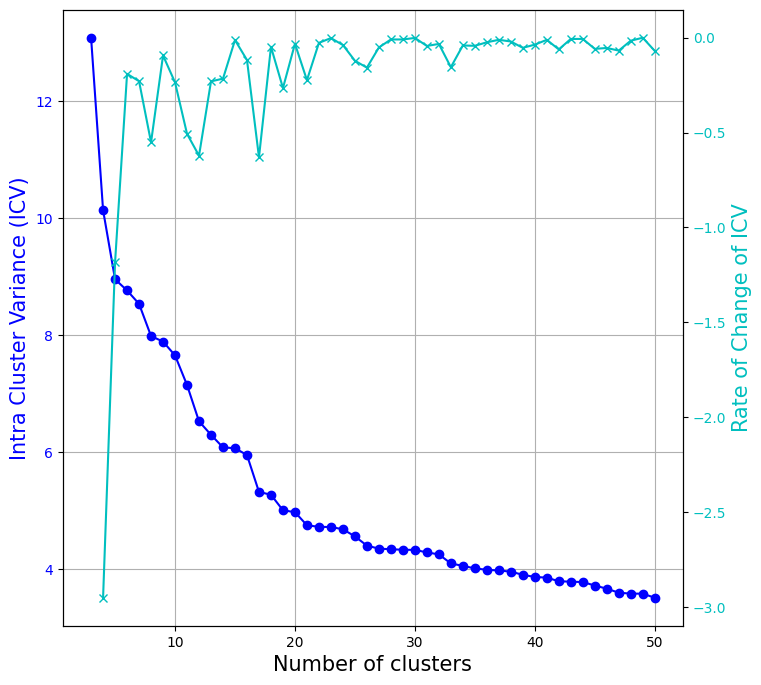

In [21]:
k_range = np.array(list(threshold_distances.keys()))
distances = np.array(list(threshold_distances.values()))
distances_dff = np.diff(distances)

# Create figure
fig, ax1 = plt.subplots(figsize=(8, 8))

# Plot threshold distances
ax1.plot(k_range, distances, marker='o', color='b', label='Threshold Distance')
ax1.set_xlabel('Number of clusters', size=15)
ax1.set_ylabel('Intra Cluster Variance (ICV)', color='b', size=15)
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True)

# Plot rate of change of threshold distances
ax2 = ax1.twinx()
ax2.plot(k_range[1:], distances_dff, marker='x', color='c', label='Rate of Change of Threshold Distance')
ax2.set_ylabel('Rate of Change of ICV', color='c', size=15)
ax2.tick_params(axis='y', labelcolor='c')

# Show plot
# plt.title('Threshold Distance and Rate of Change')
plt.savefig('../data/output/elbow_method_hierarchical_clustering.pdf', format='pdf')
plt.show()

In [22]:
# # Tune threshold for level selection for hierarchical conceptual map
# k_list_concpetual_map = k_range[np.where(distances_dff < -0.5)]
# k_list_concpetual_map

In [23]:
# df_cluster = pd.DataFrame()

# df_cluster['clusters_1'] = 0

# for k in k_list_concpetual_map:
#     clusters_HC = fcluster(Z, k, criterion='maxclust') - 1
#     df_cluster[f'clusters_{k}'] = clusters_HC

# df_cluster['clusters_1'] = 0

# df_cluster

In [24]:
# for col_idx, n_clusters in enumerate(df_cluster.columns):
#     for cluster in df_cluster[n_clusters].sort_values().unique():

#         df_topic = df_vectorized_original[df_cluster[n_clusters] == cluster]
#         centroid_words = summarize(df_topic, 5)
#         print(f'Cluster {cluster} ({df_topic.shape[0]}): {centroid_words}')

#         print(f' |---- Cluster {0}')
#     print('-'*100)

Elegir cantidad de tópicos

In [25]:
k = 20
clusters = list(range(k))
print(clusters)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


In [26]:
# Asignar el cluster correspondiente
df['cluster_HC'] = fcluster(Z, k, criterion='maxclust') - 1
print(sorted(df['cluster_HC'].unique()))
df["cluster_HC"].value_counts()

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


cluster_HC
17    854
13    755
15    748
1     493
14    475
16    419
2     385
19    360
9     292
5     266
0     219
6     189
3     187
4     185
11    176
18    155
8     154
7     144
12    106
10     71
Name: count, dtype: int64

## Kmeans

### Metodo del codo

In [27]:
# # Listas para almacenar la inercia y el Silhouette Score de cada k
# inertia = []
# silhouette_scores = []

# # Rango de k para probar
# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Calcular la inercia y el Silhouette Score para cada valor de k
# for k_value in k_range:
#     print(f"Comenzando KMeans para k={k_value}")
#     tic = time.time()

#     kmeans = KMeans(n_clusters=k_value, random_state=0, n_init=100, init='k-means++', max_iter=100)
#     kmeans.fit(X)
    
#     # Almacenar la inercia
#     inertia.append(kmeans.inertia_)
    
#     # Calcular el Silhouette Score y almacenarlo
#     score = silhouette_score(X, kmeans.labels_)
#     silhouette_scores.append(score)
    
                                
#     toc = time.time()
#     print(f"Completado en {toc - tic:.2f} segundos\n")

# # Guardar
# with open('data/output/kmeans_metrics.pkl', 'wb') as f:
#     pickle.dump({'inertia': inertia, 'silhouette_scores': silhouette_scores}, f)

# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Cargar
# with open('data/output/kmeans_metrics.pkl', 'rb') as f:
#     metrics = pickle.load(f)
# inertia = metrics['inertia']
# silhouette_scores = metrics['silhouette_scores']

# # Calcular la tasa de cambio para la inercia y el Silhouette Score
# delta_inertia = np.diff(inertia)
# delta_silhouette = np.diff(silhouette_scores)

# # Crear una figura con dos subgráficos (lado a lado)
# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# # Graficar la inercia en el primer subgráfico (izquierda)
# ax1.plot(k_range, inertia, marker='o', color='b', label='Inercia')
# ax1.set_xlabel('Número de clusters (k)')
# ax1.set_ylabel('Inercia', color='b')
# ax1.tick_params(axis='y', labelcolor='b')

# # Graficar la tasa de cambio de la inercia en el eje y derecho
# ax1_twin = ax1.twinx()
# ax1_twin.plot(k_range[1:], delta_inertia, marker='x', color='c', label='Tasa de cambio de Inercia')
# ax1_twin.set_ylabel('Tasa de cambio de Inercia', color='c')
# ax1_twin.tick_params(axis='y', labelcolor='c')

# # Título y leyenda para el primer gráfico
# ax1.set_title('Inercia y Tasa de Cambio de Inercia')
# # ax1.legend(loc='best')

# # Graficar el Silhouette Score en el segundo subgráfico (derecha)
# ax2.plot(k_range, silhouette_scores, marker='o', color='g', label='Silhouette Score')
# ax2.set_xlabel('Número de clusters (k)')
# ax2.set_ylabel('Silhouette Score', color='g')
# ax2.tick_params(axis='y', labelcolor='g')

# # Graficar la tasa de cambio del Silhouette Score en el eje y derecho
# ax2_twin = ax2.twinx()
# ax2_twin.plot(k_range[1:], delta_silhouette, marker='x', color='y', label='Tasa de cambio de Silhouette Score')
# ax2_twin.set_ylabel('Tasa de cambio de Silhouette Score', color='y')
# ax2_twin.tick_params(axis='y', labelcolor='y')

# # Título y leyenda para el segundo gráfico
# ax2.set_title('Silhouette Score y Tasa de Cambio de Silhouette Score')
# # ax2.legend(loc='best')

# # Mostrar el gráfico
# plt.tight_layout()  # Ajusta el espacio entre los subgráficos
# plt.show()

### Clustering final

In [28]:
# kmeans = KMeans(n_clusters=k, random_state=0, n_init=100, init='k-means++', max_iter=100).fit(X)
# df["cluster_KM"] = kmeans.predict(X)

# print(sorted(df['cluster_KM'].unique()))
# df["cluster_KM"].value_counts()

Clasificación de un texto

In [29]:
# predicted_cluster = kmeans.predict(topico_vec)
# print(predicted_cluster)

## Results

In [30]:
# Pintar los KNN del topico consultado
# df.loc[indices_knn[0], "cluster_HC"] = -1
# df.loc[indices_knn[0], "cluster_KM"] = -1

Choose clustering type:
* cluster_HC
* cluster_KM

In [31]:
# Select clsutering method
clustering_method = "cluster_HC"

# Convert clsuter column to categorical type
df[clustering_method] = df[clustering_method].astype('category')

In [32]:
# # PCA

# # Calcular centroides de cada cluster
# centroids = df.groupby(clustering_method)[['pca2d_1', 'pca2d_2']].mean().reset_index()

# # Crear gráfico de dispersión interactivo con leyenda discreta
# fig = px.scatter(
#     df, 
#     x='pca2d_1',
#     y='pca2d_2',
#     size=None,
#     color=clustering_method,  # Usar la columna categórica para el color
#     title='PCA 2D',
#     color_discrete_sequence=px.colors.qualitative.Alphabet,  # Usar una paleta de colores discreta
#     hover_data=[clustering_method, 'title'],  # Agregar el cluster y el título al tooltip
#     hover_name='title',  # Mostrar el título como identificador principal en el tooltip
#     opacity=0.5,
#     category_orders={clustering_method: clusters}
# )

# # Asegurar que la relación de aspecto sea 1:1 tanto en los ejes como en la figura
# fig.update_layout(
#     xaxis=dict(scaleanchor="y"),  # Vincula la escala del eje x con el eje y
#     yaxis=dict(scaleanchor="x"),  # Vincula la escala del eje y con el eje x
#     width=800,  # Establece un tamaño específico para el ancho
#     height=600,  # Establece el mismo tamaño para la altura
#     legend_title_text='Cluster'  # Personalizar el título de la leyenda
# )

# # Personalizar el formato del tooltip
# fig.update_traces(
#     marker=dict(size=5),
#     hovertemplate="<b>Title:</b> %{hovertext}<br>" +  # Título en negrita
#                   "<b>Cluster:</b> %{customdata[0]}<br>" +  # Mostrar el cluster (usando customdata)
#                   "<b>X:</b> %{x}<br>" +  # Coordenada X
#                   "<b>Y:</b> %{y}<br>" +  # Coordenada Y
#                   "<extra></extra>"  # Eliminar información adicional no deseada
# )

# # Agregar puntos resaltados en rojo, sin que aparezcan en la leyenda
# fig.add_scatter(
#     x=df.loc[knn_idxs[0], 'pca2d_1'],
#     y=df.loc[knn_idxs[0], 'pca2d_2'],
#     mode='markers',
#     marker=dict(color='red', size=10, line=dict(color='black', width=2)),
#     name='KNNs',
#     showlegend=True,
#     customdata=df.loc[knn_idxs[0], [clustering_method]],  # Asegurar que tengan los mismos datos adicionales
#     hovertext=df.loc[knn_idxs[0], 'title'],  # Usar el título también para estos puntos
#     hovertemplate="<b>Title:</b> %{hovertext}<br>" +
#                   "<b>Cluster:</b> %{customdata[0]}<br>" +
#                   "<b>X:</b> %{x}<br>" +
#                   "<b>Y:</b> %{y}<br>" +
#                   "<extra></extra>"
# )

# # Obtener los colores usados en el gráfico principal
# colors = px.colors.qualitative.Alphabet

# # Crear un diccionario que mapea cada cluster a un color
# cluster_colors = dict(zip(df[clustering_method].cat.categories, colors))

# # Agregar centroides con el color correspondiente de su cluster
# for cluster in centroids[clustering_method]:
#     centroid = centroids[centroids[clustering_method] == cluster]
#     fig.add_scatter(
#         x=centroid['pca2d_1'],
#         y=centroid['pca2d_2'],
#         mode='markers',
#         marker=dict(color=cluster_colors[cluster], size=10, symbol='x', line=dict(color='black', width=2)),
#         name=f'Centroid {cluster}',  # Opcional, si quieres que aparezca en la leyenda
#         showlegend=False
#     )

# # Mostrar el gráfico
# fig.show()

In [50]:
# UMAP

# Calcular centroides de cada cluster
centroids = df.groupby(clustering_method)[['umap2d_1', 'umap2d_2']].mean().reset_index()

# Crear gráfico de dispersión interactivo con leyenda discreta
fig = px.scatter(
    df, 
    x='umap2d_1',
    y='umap2d_2',
    size=None,
    color=clustering_method,  # Usar la columna categórica para el color
    # title='UMAP 2D',
    color_discrete_sequence=px.colors.qualitative.Alphabet,  # Usar una paleta de colores discreta
    hover_data=[clustering_method, 'title'],  # Agregar el cluster y el título al tooltip
    hover_name='title',  # Mostrar el título como identificador principal en el tooltip
    opacity=0.3,
    category_orders={clustering_method: clusters}
)

# Asegurar que la relación de aspecto sea 1:1 tanto en los ejes como en la figura
fig.update_layout(
    xaxis=dict(scaleanchor="y"),  # Vincula la escala del eje x con el eje y
    yaxis=dict(scaleanchor="x"),  # Vincula la escala del eje y con el eje x
    width=800,  # Establece un tamaño específico para el ancho
    height=800,  # Establece el mismo tamaño para la altura
    legend_title_text='Cluster',  # Personalizar el título de la leyenda
    legend_title_font_size=15,
    xaxis_title_font_size=15,
    yaxis_title_font_size=15
)

# Personalizar el formato del tooltip
fig.update_traces(
    marker=dict(size=5),
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +  # Título en negrita
                  "<b>Cluster:</b> %{customdata[0]}<br>" +  # Mostrar el cluster (usando customdata)
                  "<b>X:</b> %{x}<br>" +  # Coordenada X
                  "<b>Y:</b> %{y}<br>" +  # Coordenada Y
                  "<extra></extra>"  # Eliminar información adicional no deseada
)

# Agregar puntos resaltados en rojo, sin que aparezcan en la leyenda
fig.add_scatter(
    x=df.loc[knn_idxs[0], 'umap2d_1'],
    y=df.loc[knn_idxs[0], 'umap2d_2'],
    mode='markers',
    marker=dict(color='red', size=10, line=dict(color='black', width=2)),
    name='KNNs',
    showlegend=True,
    customdata=df.loc[knn_idxs[0], [clustering_method]],  # Asegurar que tengan los mismos datos adicionales
    hovertext=df.loc[knn_idxs[0], 'title'],  # Usar el título también para estos puntos
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +
                  "<b>Cluster:</b> %{customdata[0]}<br>" +
                  "<b>X:</b> %{x}<br>" +
                  "<b>Y:</b> %{y}<br>" +
                  "<extra></extra>"
)

# Obtener los colores usados en el gráfico principal
colors = px.colors.qualitative.Alphabet

# Crear un diccionario que mapea cada cluster a un color
cluster_colors = dict(zip(df[clustering_method].cat.categories, colors))

# Agregar centroides con el color correspondiente de su cluster
for cluster in centroids[clustering_method]:
    centroid = centroids[centroids[clustering_method] == cluster]
    fig.add_scatter(
        x=centroid['umap2d_1'],
        y=centroid['umap2d_2'],
        mode='markers',
        marker=dict(color=cluster_colors[cluster], size=10, symbol='x', line=dict(color='black', width=2)),
        name=f'Centroid {cluster}',  # Opcional, si quieres que aparezca en la leyenda
        showlegend=False
    )

# Save
fig.write_image("../data/output/UMAP.pdf")
# Mostrar el gráfico
fig.show()

C:\Users\Pablo\AppData\Local\Temp\ipykernel_13356\496450948.py:4: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



# Summarization
Importantest words by Tf-Idf score

In [34]:
def summarize(df_topic, n_centroid_words):

    # Find centroid
    centroid = df_topic.mean(axis=0)

    # Take the n first words
    centroid_words = ", ".join([words[idx] for idx in centroid.argsort()[::-1][:n_centroid_words]])
    
    # To list, remove duplicated words
    centroid_words = centroid_words.replace(',','').split(' ')
    centroid_words_temp = []
    for word in centroid_words:
        if word not in centroid_words_temp:
            centroid_words_temp.append(word)
    centroid_words = centroid_words_temp
    
    return centroid_words

### Corpus

In [35]:
df_topic = df_vectorized_original.copy()
centroid_words = summarize(df_topic, 10)
print(f'Full corpus: {centroid_words}')

# word_cloud(centroid_words)

Full corpus: ['voltage', 'converter', 'control', 'power', 'current', 'dc', 'multilevel', 'fault', 'system', 'modular']


### Clusters

In [58]:
for cluster in clusters:
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 5)
    # print(f'Cluster {cluster}: {centroid_words}')
    print(f'\item [{cluster}]: {", ".join(centroid_words)}')

    # word_cloud(centroid_words)

\item [0]: fault, detection, diagnosis, tolerant, open
\item [1]: fault, dc, protection, current, circuit
\item [2]: wind, offshore, farm, power, voltage
\item [3]: predictive, control, mpc, model, voltage
\item [4]: impedance, stability, model, wind, frequency
\item [5]: model, stability, control, voltage, system
\item [6]: model, time, simulation, transient, real
\item [7]: photovoltaic, pv, power, solar, system
\item [8]: battery, storage, vehicle, energy, electric
\item [9]: modulation, voltage, carrier, pulse, width
\item [10]: thermal, temperature, loss, junction, power
\item [11]: loss, sic, switching, voltage, converter
\item [12]: monitoring, sensor, voltage, observer, capacitor
\item [13]: voltage, converter, control, power, multilevel
\item [14]: power, voltage, energy, converter, control
\item [15]: control, voltage, converter, current, power
\item [16]: dc, voltage, converter, transformer, power
\item [17]: voltage, converter, multilevel, control, capacitor
\item [18]: mot

# Hierarchical conceptual map

In [37]:
# import networkx as nx

# # Crear el grafo dirigido
# G = nx.DiGraph()

# # Ejemplo de títulos y niveles de clusters
# niveles = {
#     0: [],
#     1: ["Cluster A", "Cluster B", "Cluster C"],
#     2: ["Cluster A1", "Cluster A2", "Cluster B1", "Cluster B2", "Cluster C1"]
# }

# # Conectar los niveles de clusters
# relaciones = [
#     ('\n'.join(centroid_words), "Cluster A"),
#     ('\n'.join(centroid_words), "Cluster B"),
#     ('\n'.join(centroid_words), "Cluster C"),
#     ("Cluster A", "Cluster A1"),
#     ("Cluster A", "Cluster A2"),
#     ("Cluster B", "Cluster B1"),
#     ("Cluster B", "Cluster B2"),
#     ("Cluster C", "Cluster C1")
# ]

# # Agregar nodos y aristas al grafo
# for nivel in niveles.values():
#     G.add_nodes_from(nivel)
# G.add_edges_from(relaciones)

# # Asignar posiciones centradas a los nodos
# pos = {}
# max_width = max(len(nodos) for nodos in niveles.values())

# for nivel, nodos in niveles.items():
#     offset = (max_width - len(nodos)) / 2
#     for i, nodo in enumerate(nodos):
#         pos[nodo] = (i + offset, -nivel)

# # Dibujar el mapa conceptual jerárquico
# plt.figure(figsize=(8, 6))
# nx.draw(G, pos, with_labels=True, node_size=3000, node_color='lightblue', font_size=10, font_weight='bold', edge_color='gray')
# plt.title("Mapa Conceptual Jerárquico")
# plt.show()

# Documento representativo
En corpus completo y por clusters

## Centroides

In [38]:
# def encontrar_mas_cercano_al_centroide(df_vectorized, data):
#     centroide = df_vectorized.mean(axis=0)
#     distancias = euclidean_distances(df_vectorized, [centroide])
#     indice_mas_cercano = np.argmin(distancias)
#     texto_mas_cercano = data.iloc[indice_mas_cercano]['abstract']
#     titulo = data.iloc[indice_mas_cercano]['title']
#     return titulo, texto_mas_cercano

### Corpus

In [39]:
# titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(df_vectorized, data)
# display(f"Texto mas representativo del corpus:")
# display(f"Título: {titulo}")
# display(f"Abstract: {texto_mas_cercano}")

### Clusters

In [40]:
# for cluster in clusters:
#     cluster_data_vectorized = df_vectorized.loc[(df[clustering_method] == cluster).values]
#     cluster_data = data[df[clustering_method] == cluster]
#     titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(cluster_data_vectorized, cluster_data)
#     display(f"Cluster {cluster}: Texto mas cercano al centroide")
#     display(f"Título: {titulo}")
#     display(f"Abstract: {texto_mas_cercano}")

## Puntaje Tfidf
Le llamaremos representante al abstract que tenga una mayor cantidad de frecuencia acumulada de palabras del tfid vectorizer, ya que eso implica una mayor participación (profundizar).

Disclaimer: Tenía razón en dudad del método. esto en verdad lo k hace es elegir al que tiene mayor interaccion entre palabras, es decir, el abstract mas complejo.

### Corpus

In [41]:
# abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
# print("Texto más representativo del corpus:")
# print(f"Título: {data['title'].iloc[abstract00]}")
# print(f"Abstract: {data['abstract'].iloc[abstract00]}")

### Clusters

In [42]:
# abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
# display("Texto más representativo del corpus:")
# display(f"Título: {data['title'].iloc[abstract00]}")
# display(f"Abstract: {data['abstract'].iloc[abstract00]}")

In [43]:
# for cluster in clusters:
#     abstract00 = df_vectorized.loc[(df[clustering_method] == cluster).values].sum(axis=1).sort_values(ascending=False).index[0]
#     display(f"Cluster {cluster}: Texto mas representativo")
#     display(f"Título: {data['title'].iloc[abstract00]}")
#     display(f"Abstract: {data['abstract'].iloc[abstract00]}")

Anti representantes (abstracts con baja participación en el tfid vectorizer)

In [44]:
# representantes = [df_vectorized.loc[df[df[clustering_method] == idx].index].sum(axis=1).sort_values().index[0] for idx in clusters]
# for rep in representantes:
#   print('\nTítulo:')
#   display(data.iloc[rep]['title'])
#   print('\nAbstract')
#   display(data.iloc[rep]['Abstract'])

## Similaridad del coseno

### Corpus

In [45]:
# abstract00 = RepresentanteCoseno(df_vectorized)
# titulo = data["title"].iloc[abstract00]
# abstract_mas_representativo = data["abstract"].iloc[abstract00]

# display(f"Texto mas similar a todos los demas en el corpus:")
# display(f"Título: {titulo}")
# display(f"Abstract: {abstract_mas_representativo}")

### Clusters

In [46]:
# for cluster in clusters:
#     abstract00 = RepresentanteCoseno(df_vectorized.loc[(df[clustering_method] == cluster).values])
#     titulo = data["title"].iloc[abstract00]
#     abstract_mas_representativo = data["abstract"].iloc[abstract00]
#     display(f"Cluster {cluster}: Texto mas similar a todos en el cluster")
#     display(f"Título: {titulo}")
#     display(f"Abstract: {abstract_mas_representativo}")

# Grafo de palabras

## Palabras de un abstract especifico

In [47]:
# # Obtener el texto del dataframe
# texto = df.iloc[1000]["abstract"]

# # Procesar el texto con spaCy
# doc = nlp(texto)

# # Crear grafo dirigido con NetworkX
# G = nx.DiGraph()
# for token in doc:
#     if not token.is_stop and not token.is_punct:
#         G.add_node(token.text)
#     for child in token.children:
#         if not child.is_stop and not child.is_punct:
#             G.add_edge(token.text, child.text)

# # Calcular importancia con PageRank
# pagerank = nx.pagerank(G)

# # Crear el grafo con Graphviz
# dot = Digraph(format="png")
# dot.attr(dpi="300", rankdir="LR", bgcolor="white")

# # Agregar nodos con tamaño basado en PageRank
# max_pr = max(pagerank.values()) if pagerank else 1
# for node, pr in pagerank.items():
#     size = str(int(10 + (pr / max_pr) * 30))  # Tamaño proporcional
#     dot.node(node, fontsize=size, shape="ellipse", style="filled", fillcolor="lightblue")

# # Agregar aristas
# for u, v in G.edges():
#     dot.edge(u, v, color="black", penwidth="1.5")

# # Renderizar el grafo en un archivo temporal
# output_file = "Data/Figuras/grafo"
# dot.render(output_file, format="png", cleanup=True)
# # Mostrar la imagen en Jupyter Notebook
# display(Image(filename=output_file + ".png"))

## Entre clusters